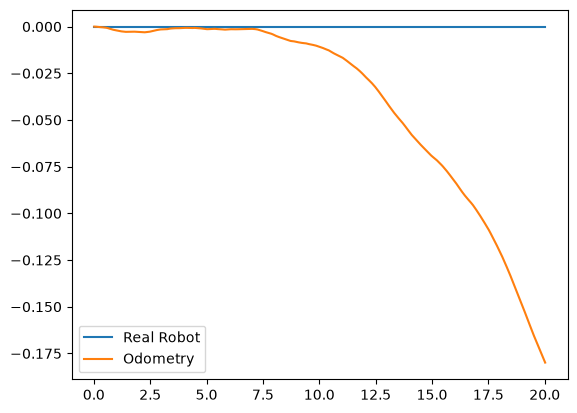

In [65]:
#
#
import arslabrobotics as ar
import numpy as np
import random
import matplotlib.pyplot as plt

class CartModel:

    def __init__(self, wb):
        self.wheelbase = wb
        self.x = 0
        self.y = 0
        self.theta = 0

    def evaluate(self, delta_t, vl, vr):
        self.v = (vl + vr) / 2
        self.w = (vr - vl) / self.wheelbase
        self.delta_p = self.v * delta_t
        delta_theta = self.w * delta_t
        self.x = self.x + self.delta_p * np.cos(self.theta)
        self.y = self.y + self.delta_p * np.sin(self.theta)
        self.theta = ar.utils.normalize_angle(self.theta + delta_theta)

    def jacob(self):
        return np.array( [ [ 1, 0, -self.delta_p * np.sin(self.theta) ],
                           [ 0, 1, self.delta_p * np.cos(self.theta) ],
                           [ 0, 0, 1 ] ])
    def state(self):
        return np.array( [ [self.x], [self.y], [self.theta] ] )

    def update_state(self, x):
        self.x = x[0,0]
        self.y = x[1,0]
        self.theta = x[2,0]
        
delta_t = 0.01

real_cart = CartModel(0.3)
modeled_cart = CartModel(0.3)

real_x = []
real_y = []
model_x = []
model_y = []

tm = ar.utils.Time(use_fake_time = True)
tm.start()

while tm.get() < 10:
    vl = 2.0
    vr = 2.0
    tm.sleep(delta_t)
    tm.elapsed()
    real_cart.evaluate(delta_t, vl, vr)
    real_x.append(real_cart.x)
    real_y.append(real_cart.y)
    
    vl += np.random.normal(0,1e-2)
    vr += np.random.normal(0,1e-2)
    modeled_cart.evaluate(delta_t, vl, vr)
    model_x.append(modeled_cart.x)
    model_y.append(modeled_cart.y)

plt.plot(real_x, real_y, label = "Real Robot")
plt.plot(model_x, model_y, label = "Odometry")
plt.legend()
plt.show()


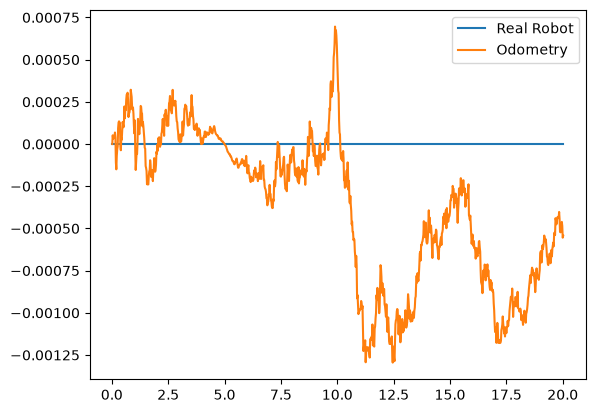

In [66]:

Xm = 5
Ym = 5

real_cart = CartModel(0.3)
modeled_cart = CartModel(0.3)

real_x = []
real_y = []
model_x = []
model_y = []

tm = ar.utils.Time(use_fake_time = True)
tm.start()

# process noise
Q = np.eye(3) * 1e-1

# measurement noise
R = np.eye(2) * 1e-6

# error covariance
P = np.eye(3)

while tm.get() < 10:
    vl = 2.0
    vr = 2.0
    tm.sleep(delta_t)
    tm.elapsed()
    real_cart.evaluate(delta_t, vl, vr)
    real_x.append(real_cart.x)
    real_y.append(real_cart.y)

    # --------------------- PREDICT
    vl += np.random.normal(0,1e-2)
    vr += np.random.normal(0,1e-2)
    modeled_cart.evaluate(delta_t, vl, vr)
    model_x.append(modeled_cart.x)
    model_y.append(modeled_cart.y)

    A = modeled_cart.jacob()
    # update error covariance
    P = A @ P @ A.T + Q

    # read real measure for marker (LIDAR from real cart)
    dx = Xm - real_cart.x
    dy = Ym - real_cart.y
    r = np.linalg.norm( [ dx, dy ] )
    alpha = ar.utils.normalize_angle(np.atan2(dy, dx) - real_cart.theta)
    z = np.array( [ [r], [alpha] ])

    # read expected measures
    dx = Xm - modeled_cart.x
    dy = Ym - modeled_cart.y
    r_p = np.linalg.norm( [ dx, dy ] )
    alpha_p = ar.utils.normalize_angle(np.atan2(dy, dx) - modeled_cart.theta)
    z_p = np.array( [ [r_p], [alpha_p] ])

    # measure jacobian
    H = np.array( [ [ - dx / r_p, - dy / r_p, 0],
                    [ dy / (r_p**2), - dx / (r_p**2), -1 ] ] )
    
    # --------------------- UPDATE
    S = (H @ P @ H.T + R)
    K = P @ H.T @ np.linalg.inv(S)

    # --------------------- ERROR CORRECTION
    x = modeled_cart.state() 
    x = x + K @ (z - z_p)
    modeled_cart.update_state(x)
    P = (np.eye(3) - K @ H) @ P

plt.plot(real_x, real_y, label="Real Robot")
plt.plot(model_x, model_y, label="Odometry")
plt.legend()
plt.show()

